---
---

<h1><center><ins>Numerical Methods: Exam 1</ins></center></h1>
<h2><center>November 11, 09:45-11:15 </center></h2>

Please answer the short questions related to the numerical methods we discussed during the lectures. Provide short and concise (one-two sentences) answers.

Solve the two exercises in the python notebook, *documenting your code* where needed, or create .py files that are documented.

Remember to answer any discussion points asked in the question to obtain maximum points.  

***Before 11:20*** your files need to be uploaded to GitHub.<br>
<br>
This means you have roughly 90 minutes to complete the exercises and answer the questions.

You may use the lecture notes and any of your exercises freely, but you can **not** use ChatGPT code assistant or other AI coding tools such as Claude.<br> 
**_Collaboration or plagarized code except your own is prohibited and no phones or communication will be allowed_**.

---
---

## Short questions
1. Name the root-finding methods we have discussed during the lectures, and rank them by their precision. Do all methods always converge? (**2 points**)
2. What is the difference between the trapezoid rule and the Simpson's rule in the Newton-Cotes numerical integration? (**2 points**)
3. What is the simplest way of expanding 1D interpolation methods to 2D? (**2 points**) 
4. What is LU decomposition and why is it used when solving sets of linear algebraic equations? (**2 points**)
5. What is the Jacobian matrix in the Newton-Raphson Method for nonlinear systems of equations? Can the Newton-Raphson method always find a solution for a nonlinear system of equations? (**2 points**)

Frage 1
Ranking: Bisection, Secant method, Newton-Raphson method. Only Bisection converges always.

Frage 2
Trapezoid rule uses straight lines, Simpson´s rule uses polynomials.

Frage 3
Bi-linear and bi-cubic interpolation.

Frage 4
LU decomposition splits the A matrix in two matrixes. A = LU. Its reusable and faster than the inverse.

Frage 5
The Newton-Raphson method is not guaranteed to succeed. 

## Exercise 1. Interpolating the luminosity profile of a galaxy (10 Points)

Imagine an elliptical galaxy with the light intensity profile described by the de Vaucouleurs's law. We have observed four datapoints for the intensity in units of $L_\odot/pc^2$ at the corresponding radii in pc:

\begin{aligned}
(R_0,I_0) &= (0,\;2.14\times10^5),\\
(R_1,I_1) &= (1000,\;1.14\times10^3),\\
(R_2,I_2) &= (1500,\;5.51\times10^2),\\
(R_3,I_3) &= (2000,\;3.36\times10^2).
\end{aligned}


Use the Lagrange polynomial interpolation to fit a polynomial to these datapoints.

**(a)** What is the highest polynomial degree that you can fit to the four datapoints? (**1 point**)

**(b)** Interpolate the datapoints using your polynomial (**5 points** if you use your own Lagrange polynomial, **1 point** if you use embedded python fucntions).

**(c)** Use embedded functions for numerical integration such as **quad** or **simpson** to integrate your Lagrange polynomial that represents your luminosity profile from zero to 2000 pc to obtain the approximate luminosity of the galaxy in $L_\odot$. Use the print command to show the result (**2 points**)

**(d)** Plot your results: the four datapoints and the polynomial that you used to interpolate the function (**2 points**)


(a.)

Damit kann man maximal ein Polynom vom Grad 3 eindeutig fitten.

In [8]:
# (b.)

import numpy as np

R = np.array([0., 1000., 1500., 2000.])         
I = np.array([2.14e5, 1.14e3, 5.51e2, 3.36e2])  

def lagrange(x, xd, yd):
    """Lagrange-Interpolationspolynom durch (xd, yd), ausgewertet an x."""
    x = np.asarray(x, dtype=float)
    P = np.zeros_like(x)
    for j in range(len(xd)):
        L = np.ones_like(x)                      
        for m in range(len(xd)):
            if m != j:
                L *= (x - xd[m]) / (xd[j] - xd[m])
        P += yd[j] * L
    return P


print("P(R_i) =", lagrange(R, R, I))


R_fine = np.linspace(0, 2000, 500)
I_interp = lagrange(R_fine, R, I)

P(R_i) = [214000.   1140.    551.    336.]


In [9]:
# (c.)

from scipy.integrate import quad, simpson

f = lambda r: float(lagrange(r, R, I)) 

L_quad, err = quad(f, 0, 2000)
print(f"Leuchtkraft (quad):    L = {L_quad:.4e} L_sun  (Fehler ~ {err:.1e})")

r = np.linspace(0, 2000, 501)
L_simp = simpson(lagrange(r, R, I), x=r)
print(f"Leuchtkraft (simpson): L = {L_simp:.4e} L_sun")


Leuchtkraft (quad):    L = 7.2965e+07 L_sun  (Fehler ~ 8.3e-07)
Leuchtkraft (simpson): L = 7.2965e+07 L_sun


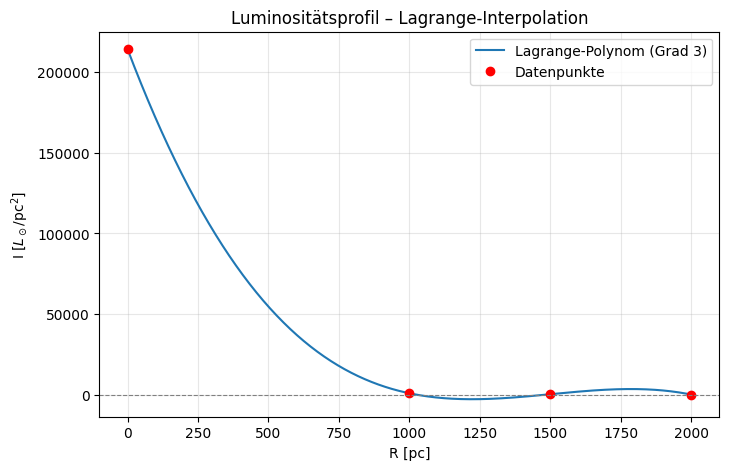

In [10]:
# (d.)

import matplotlib.pyplot as plt

R_fine = np.linspace(0, 2000, 500)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(R_fine, lagrange(R_fine, R, I), label='Lagrange-Polynom (Grad 3)')
ax.plot(R, I, 'o', color='red', label='Datenpunkte')
ax.axhline(0, color='gray', lw=0.8, ls='--')
ax.set_xlabel('R [pc]')
ax.set_ylabel(r'I [$L_\odot$/pc$^2$]')
ax.set_title('Luminositätsprofil – Lagrange-Interpolation')
ax.legend()
ax.grid(alpha=0.3)
plt.show()


## Exercise 2. Decelerating satellite and numerical derivation (10 Points)

A small spacecraft is decelerating. It's time-dependent coordinate is given by the following equation (the time is in seconds and the distance is in meters):

$$x(t) = 100 - 50 \exp (-0.2t)$$

**(a)** Determine the spacecraft's speed at $t=5$ s using the forward and central finite-difference methods (the non-symmetrical and symmetrical methods of calculating the numerical derivative) for the $dt = 1$ s (**2 points**)

**(b)** Investigate the accuracy of both methods for different step sizes. Create an array of step sizes ranging from 0.1 s to 2 s and calculate the derivatives for each $dt$ (**2 points**). Compare to the precise analytical formula for speed at $t=5$ s (**2 points**)

**(c)** Plot your results from **(b)** (**2 points**)

**(d)** Which method is more accurate, the central method or the forward method? (**1 point**). Why is one method more accurate than the other from the mathematical point of view (one sentence explanation is enough; **1 point**)



In [11]:
# (a)

import numpy as np
import matplotlib.pyplot as plt

x = lambda t: 100 - 50*np.exp(-0.2*t)        
v_exact = lambda t: 10*np.exp(-0.2*t)    

def forward(f, t, dt):
    return (f(t + dt) - f(t)) / dt

def central(f, t, dt):
    return (f(t + dt) - f(t - dt)) / (2*dt)

t0, dt = 5.0, 1.0
print(f"Forward:    v(5) = {forward(x, t0, dt):.5f} m/s")
print(f"Central:    v(5) = {central(x, t0, dt):.5f} m/s")
print(f"Analytisch: v(5) = {v_exact(t0):.5f} m/s")

Forward:    v(5) = 3.33426 m/s
Central:    v(5) = 3.70337 m/s
Analytisch: v(5) = 3.67879 m/s


In [12]:
# (b)

dts = np.linspace(0.1, 2, 20)
v_fwd = forward(x, t0, dts)
v_cen = central(x, t0, dts)
v_ex  = v_exact(t0)

err_fwd = np.abs(v_fwd - v_ex)
err_cen = np.abs(v_cen - v_ex)

print(f"{'dt':>5} {'v_fwd':>10} {'v_cen':>10} {'err_fwd':>10} {'err_cen':>10}")
for d, a, b, c, e in zip(dts, v_fwd, v_cen, err_fwd, err_cen):
    print(f"{d:5.2f} {a:10.5f} {b:10.5f} {c:10.2e} {e:10.2e}")

   dt      v_fwd      v_cen    err_fwd    err_cen
 0.10    3.64225    3.67904   3.65e-02   2.45e-04
 0.20    3.60619    3.67978   7.26e-02   9.81e-04
 0.30    3.57061    3.68100   1.08e-01   2.21e-03
 0.40    3.53549    3.68272   1.43e-01   3.93e-03
 0.50    3.50084    3.68493   1.78e-01   6.13e-03
 0.60    3.46664    3.68763   2.12e-01   8.84e-03
 0.70    3.43289    3.69082   2.46e-01   1.20e-02
 0.80    3.39958    3.69451   2.79e-01   1.57e-02
 0.90    3.36671    3.69869   3.12e-01   1.99e-02
 1.00    3.33426    3.70337   3.45e-01   2.46e-02
 1.10    3.30224    3.70854   3.77e-01   2.97e-02
 1.20    3.27063    3.71421   4.08e-01   3.54e-02
 1.30    3.23944    3.72038   4.39e-01   4.16e-02
 1.40    3.20865    3.72705   4.70e-01   4.83e-02
 1.50    3.17825    3.73423   5.01e-01   5.54e-02
 1.60    3.14825    3.74190   5.31e-01   6.31e-02
 1.70    3.11864    3.75008   5.60e-01   7.13e-02
 1.80    3.08941    3.75877   5.89e-01   8.00e-02
 1.90    3.06055    3.76797   6.18e-01   8.92e-02


(d)

The central method is more accurate. 